# valesska_sanchez_lab15 – Detección de malaria en glóbulos rojos
Clasificación binaria de glóbulos rojos: **Parasitized** (infectado por *Plasmodium*) vs **Uninfected**.
Transfer Learning con **MobileNetV2** → exportación a `blood_cells_model.tflite` **con metadatos** para ML Kit Custom Image Labeling.

Dataset: *Malaria Cell Images* (NIH / National Library of Medicine), 27 558 imágenes de glóbulos rojos de frotis teñidos con Giemsa.

**Antes de empezar:** `Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)`.

## 1. Descarga del dataset (Kaggle: iarunava/cell-images-for-detecting-malaria)

In [1]:
# kagglehub descarga datasets públicos sin necesidad de kaggle.json
!pip -q install kagglehub
import kagglehub, os, glob
path = kagglehub.dataset_download("iarunava/cell-images-for-detecting-malaria")

# El zip trae la carpeta duplicada (cell_images/cell_images); buscamos la que tiene las 2 clases
DATA_DIR = None
for root, dirs, _ in os.walk(path):
    if "Parasitized" in dirs and "Uninfected" in dirs:
        DATA_DIR = root
        break
print("DATA_DIR:", DATA_DIR)

CLASS_NAMES = ["Parasitized", "Uninfected"]
for c in CLASS_NAMES:
    print(c, len(glob.glob(os.path.join(DATA_DIR, c, "*.png"))), "imágenes")

Using Colab cache for faster access to the 'cell-images-for-detecting-malaria' dataset.
DATA_DIR: /kaggle/input/cell-images-for-detecting-malaria/cell_images
Parasitized 13779 imágenes
Uninfected 13779 imágenes


In [2]:
import tensorflow as tf, numpy as np, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

IMG_SIZE = (224, 224)
BATCH = 32
SEED = 42

paths, labels = [], []
for i, c in enumerate(CLASS_NAMES):
    files = sorted(glob.glob(os.path.join(DATA_DIR, c, "*.png")))
    paths += files
    labels += [i] * len(files)
paths, labels = np.array(paths), np.array(labels)

p_train, p_tmp, y_train, y_tmp = train_test_split(paths, labels, test_size=0.2, stratify=labels, random_state=SEED)
p_val, p_test, y_val, y_test = train_test_split(p_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=SEED)
print("train:", len(p_train), "| val:", len(p_val), "| test:", len(p_test))

def load(path, label):
    img = tf.io.decode_png(tf.io.read_file(path), channels=3)
    img = tf.image.resize(img, IMG_SIZE)            # float32 en rango 0-255
    return img, tf.one_hot(label, len(CLASS_NAMES))

def make_ds(p, y, shuffle):
    ds = tf.data.Dataset.from_tensor_slices((p, y))
    if shuffle:
        ds = ds.shuffle(len(p), seed=SEED)
    return ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_data = make_ds(p_train, y_train, True)
val_data   = make_ds(p_val,   y_val,   False)
test_data  = make_ds(p_test,  y_test,  False)

train: 22046 | val: 2756 | test: 2756


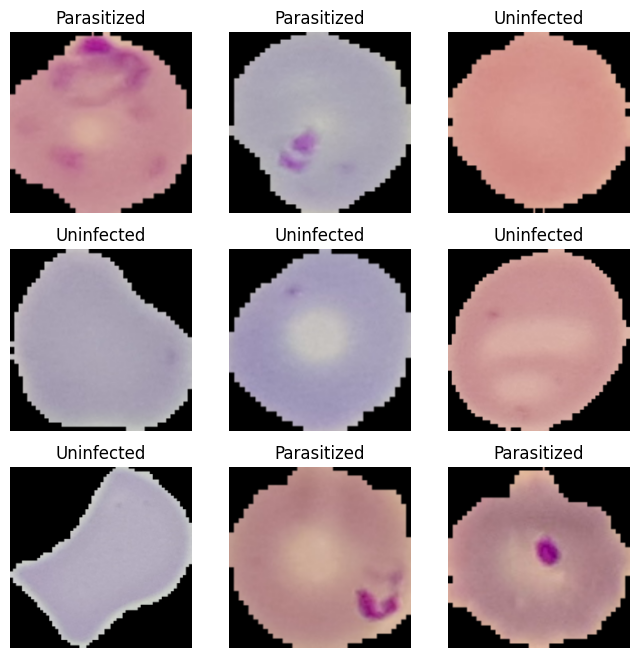

In [3]:
# Vista rápida de muestras
plt.figure(figsize=(8, 8))
for imgs, lbls in train_data.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(imgs[i].numpy().astype("uint8"))
        plt.title(CLASS_NAMES[np.argmax(lbls[i])]); plt.axis("off")

In [4]:
from tensorflow.keras import layers

augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
], name="augmentation")

base = tf.keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,),
                                         include_top=False, weights="imagenet")
base.trainable = False

inputs = tf.keras.Input(shape=IMG_SIZE + (3,), name="image")   # píxeles 0-255
x = augment(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(CLASS_NAMES), activation="softmax", name="probs")(x)
model = tf.keras.Model(inputs, outputs)

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probs (Dense)                   │ (None, 2)              │         2,562 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,260,546 (8.62 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 3.1 Fase 1 – entrenar sólo la cabeza

In [5]:
history1 = model.fit(train_data, validation_data=val_data, epochs=3)

Epoch 1/3
689/689 ━━━━━━━━━━━━━━━━━━━━ 90s 101ms/step - accuracy: 0.8816 - loss: 0.2886 - val_accuracy: 0.9271 - val_loss: 0.2053
Epoch 2/3
689/689 ━━━━━━━━━━━━━━━━━━━━ 45s 65ms/step - accuracy: 0.9155 - loss: 0.2279 - val_accuracy: 0.9369 - val_loss: 0.1926
Epoch 3/3
689/689 ━━━━━━━━━━━━━━━━━━━━ 46s 67ms/step - accuracy: 0.9173 - loss: 0.2204 - val_accuracy: 0.9274 - val_loss: 0.1955


### 3.2 Fase 2 – fine-tuning de las últimas capas

In [6]:
base.trainable = True
for layer in base.layers[:100]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])
cb = [tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=2,
                                       restore_best_weights=True)]
history2 = model.fit(train_data, validation_data=val_data, epochs=6, callbacks=cb)

Epoch 1/6
689/689 ━━━━━━━━━━━━━━━━━━━━ 88s 109ms/step - accuracy: 0.9110 - loss: 0.2582 - val_accuracy: 0.9329 - val_loss: 0.2213
Epoch 2/6
689/689 ━━━━━━━━━━━━━━━━━━━━ 73s 106ms/step - accuracy: 0.9360 - loss: 0.1906 - val_accuracy: 0.9510 - val_loss: 0.1740
Epoch 3/6
689/689 ━━━━━━━━━━━━━━━━━━━━ 73s 106ms/step - accuracy: 0.9448 - loss: 0.1665 - val_accuracy: 0.9543 - val_loss: 0.1627
Epoch 4/6
689/689 ━━━━━━━━━━━━━━━━━━━━ 73s 106ms/step - accuracy: 0.9508 - loss: 0.1487 - val_accuracy: 0.9575 - val_loss: 0.1427
Epoch 5/6
689/689 ━━━━━━━━━━━━━━━━━━━━ 81s 105ms/step - accuracy: 0.9531 - loss: 0.1417 - val_accuracy: 0.9590 - val_loss: 0.1350
Epoch 6/6
689/689 ━━━━━━━━━━━━━━━━━━━━ 73s 105ms/step - accuracy: 0.9545 - loss: 0.1296 - val_accuracy: 0.9586 - val_loss: 0.1339


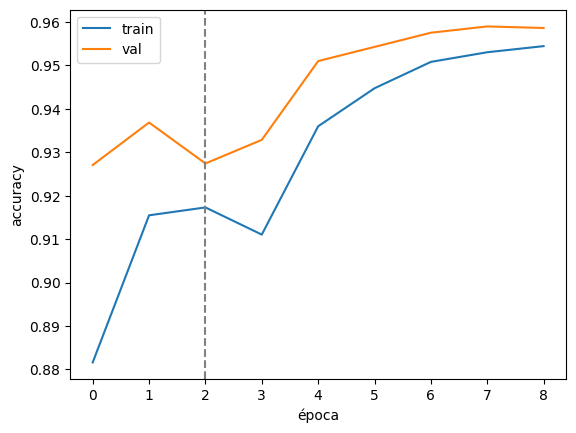

In [7]:
acc = history1.history["accuracy"] + history2.history["accuracy"]
val = history1.history["val_accuracy"] + history2.history["val_accuracy"]
plt.plot(acc, label="train"); plt.plot(val, label="val")
plt.axvline(len(history1.history["accuracy"]) - 1, ls="--", c="gray")
plt.xlabel("época"); plt.ylabel("accuracy"); plt.legend(); plt.show()

## 4. Evaluación en test_data  (captura esta celda para la diapositiva: Accuracy > 0.70)

In [8]:
loss, acc = model.evaluate(test_data)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {acc:.4f}")
assert acc > 0.70, "No supera 0.70: entrena más épocas de fine-tuning"

87/87 ━━━━━━━━━━━━━━━━━━━━ 8s 88ms/step - accuracy: 0.9572 - loss: 0.1223
Test Loss: 0.1223
Test Accuracy: 0.9572


In [9]:
# Matriz de confusión / reporte por clase
from sklearn.metrics import classification_report, confusion_matrix
y_pred = np.argmax(model.predict(test_data), 1)
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES))
print(confusion_matrix(y_test, y_pred))

87/87 ━━━━━━━━━━━━━━━━━━━━ 7s 65ms/step
              precision    recall  f1-score   support

 Parasitized       0.98      0.94      0.96      1378
  Uninfected       0.94      0.98      0.96      1378

    accuracy                           0.96      2756
   macro avg       0.96      0.96      0.96      2756
weighted avg       0.96      0.96      0.96      2756

[[1292   86]
 [  32 1346]]


## 5. Inferencia individual (np.expand_dims + np.argmax)  — captura para la diapositiva

C132P93ThinF_IMG_20151004_151811_cell_146.png -> Predicción: Parasitized (90.64%)


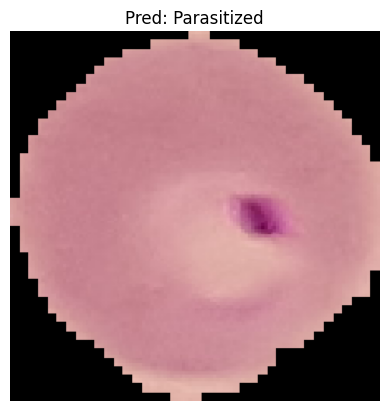

'Parasitized'

In [10]:
from tensorflow.keras.utils import load_img, img_to_array

def predict_image(img_path):
    img = load_img(img_path, target_size=IMG_SIZE)
    x = img_to_array(img)               # (224,224,3) en 0-255
    x = np.expand_dims(x, axis=0)       # (1,224,224,3)
    pred = model.predict(x, verbose=0)
    idx = np.argmax(pred[0])
    print(f"{os.path.basename(img_path)} -> Predicción: {CLASS_NAMES[idx]} ({pred[0][idx]:.2%})")
    plt.imshow(img); plt.title(f"Pred: {CLASS_NAMES[idx]}"); plt.axis("off"); plt.show()
    return CLASS_NAMES[idx]

predict_image(p_test[y_test == 0][0])

### 5.1 Prueba de 4 imágenes (2 por clase, del conjunto de test)
Se guardan en `test_images/` con el nombre que usa la app (`res/drawable`).

Real: Parasitized | C132P93ThinF_IMG_20151004_151811_cell_146.png -> Predicción: Parasitized (90.64%)


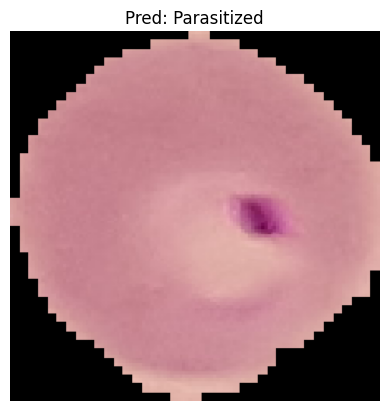

Real: Parasitized | C118P79ThinF_IMG_20151002_105018_cell_139.png -> Predicción: Uninfected (96.86%)


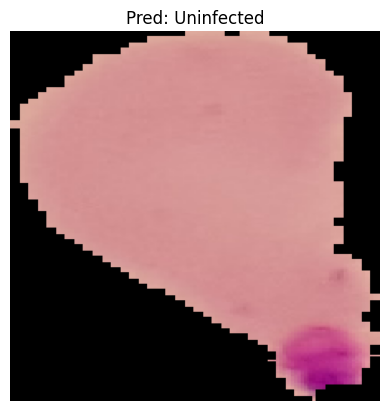

Real: Uninfected | C72P33_ThinF_IMG_20150815_105033_cell_151.png -> Predicción: Uninfected (99.13%)


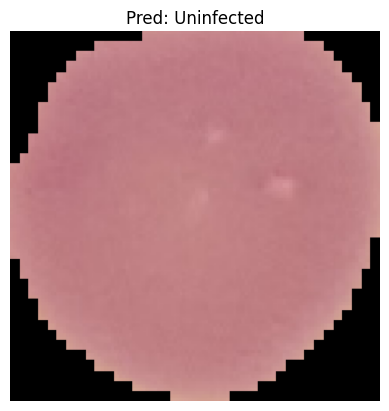

Real: Uninfected | C102P63ThinF_IMG_20150918_162155_cell_119.png -> Predicción: Uninfected (99.98%)


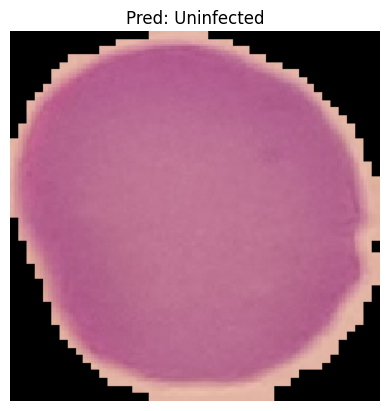

['cell_parasitized_1.png', 'cell_parasitized_2.png', 'cell_uninfected_1.png', 'cell_uninfected_2.png']


In [11]:
import shutil
os.makedirs("test_images", exist_ok=True)
for i, c in enumerate(CLASS_NAMES):
    for k, p in enumerate(p_test[y_test == i][:2], start=1):
        print("Real:", c, end=" | ")
        predict_image(p)
        shutil.copy(p, f"test_images/cell_{c.lower()}_{k}.png")
print(sorted(os.listdir("test_images")))

In [12]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()
with open("model_raw.tflite", "wb") as f:
    f.write(tflite_model)

# Etiquetas (orden = índice de salida)
with open("labels.txt", "w") as f:
    f.write("\n".join(CLASS_NAMES))

interp = tf.lite.Interpreter(model_path="model_raw.tflite"); interp.allocate_tensors()
print(interp.get_input_details()[0]["shape"], interp.get_input_details()[0]["dtype"])
print(interp.get_output_details()[0]["shape"])

Saved artifact at '/tmp/tmpxax2bqom'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  140665023615760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140665023490640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140665023486416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140665022200336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140665022192080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140665023480272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140665023489296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140665023480464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140665023486608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140665023489104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140665023796368: Tens

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [13]:
%%writefile add_metadata.py
from tflite_support.metadata_writers import image_classifier, writer_utils
writer = image_classifier.MetadataWriter.create_for_inference(
    writer_utils.load_file("model_raw.tflite"),
    input_norm_mean=[0.0], input_norm_std=[1.0],   # el modelo ya normaliza internamente
    label_file_paths=["labels.txt"])
writer_utils.save_file(writer.populate(), "blood_cells_model.tflite")
print(writer.get_metadata_json())

Writing add_metadata.py


In [14]:
!pip -q install uv
!uv venv -q --python 3.10 /content/py310
!uv pip install -q --python /content/py310/bin/python tflite-support==0.4.4 "numpy<2"
!/content/py310/bin/python add_metadata.py

{
  "name": "ImageClassifier",
  "description": "Identify the most prominent object in the image from a known set of categories.",
  "subgraph_metadata": [
    {
      "input_tensor_metadata": [
        {
          "name": "image",
          "description": "Input image to be classified.",
          "content": {
            "content_properties_type": "ImageProperties",
            "content_properties": {
              "color_space": "RGB"
            }
          },
          "process_units": [
            {
              "options_type": "NormalizationOptions",
              "options": {
                "mean": [
                  0.0
                ],
                "std": [
                  1.0
                ]
              }
            }
          ],
          "stats": {
            "max": [
              255.0
            ],
            "min": [
              0.0
            ]
          }
        }
      ],
      "output_tensor_metadata": [
        {
          "name": "probabil

In [15]:
interp = tf.lite.Interpreter(model_path="blood_cells_model.tflite"); interp.allocate_tensors()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
for f in sorted(os.listdir("test_images")):
    x = np.expand_dims(img_to_array(load_img(f"test_images/{f}", target_size=IMG_SIZE)), 0).astype(np.float32)
    interp.set_tensor(inp["index"], x); interp.invoke()
    print(f, "->", CLASS_NAMES[np.argmax(interp.get_tensor(out["index"])[0])])

!zip -q -r entregables.zip blood_cells_model.tflite labels.txt test_images
from google.colab import files
files.download("entregables.zip")   # contiene el .tflite y las 4 imágenes para res/drawable

cell_parasitized_1.png -> Parasitized
cell_parasitized_2.png -> Uninfected
cell_uninfected_1.png -> Uninfected
cell_uninfected_2.png -> Uninfected


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
import shutil, os
os.makedirs("mas_pruebas", exist_ok=True)
for i, c in enumerate(CLASS_NAMES):
    for k, p in enumerate(p_test[y_test == i][10:25], start=1):
        shutil.copy(p, f"mas_pruebas/{c.lower()}_{k:02d}.png")
!zip -q -r mas_pruebas.zip mas_pruebas
print("Listo:", len(os.listdir("mas_pruebas")), "imágenes")


Listo: 30 imágenes
